In [1]:
print("FraudLens project has started")

FraudLens project has started


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
print("pandas:",pd.__version__)
print("numpy:",np.__version__)
print("Matplotlib:",plt.matplotlib.__version__)

pandas: 2.3.0
numpy: 2.3.1
Matplotlib: 3.10.3


In [5]:
import os

In [6]:
print(os.path.exists("../data/train_transaction.csv"))

True


In [7]:
df_sample = pd.read_csv("../data/train_transaction.csv",nrows=1000)
df_sample.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
print("Rows",df_sample.shape[0])
print("Columns",df_sample.shape[1])

Rows 1000
Columns 394


In [10]:
print(df_sample.columns.tolist())

['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V79', 'V80', 'V81', 'V

In [11]:
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 3.0+ MB


In [13]:
missing = df_sample.isnull().sum()
missing

TransactionID       0
isFraud             0
TransactionDT       0
TransactionAmt      0
ProductCD           0
                 ... 
V335              847
V336              847
V337              847
V338              847
V339              847
Length: 394, dtype: int64

In [14]:
print(df_sample["isFraud"].value_counts())

isFraud
0    985
1     15
Name: count, dtype: int64


In [15]:
print(df_sample["isFraud"].value_counts(normalize=True)*100)

isFraud
0    98.5
1     1.5
Name: proportion, dtype: float64


In [16]:
df_sample.groupby("isFraud")["TransactionAmt"].agg(
    ["count","mean","median","min","max"]
)

,count,mean,median,min,max
isFraud,,,,,
0,985,159.930593,60.00,1.896,3162.95
1,15,143.429000,83.38,10.000,774.00


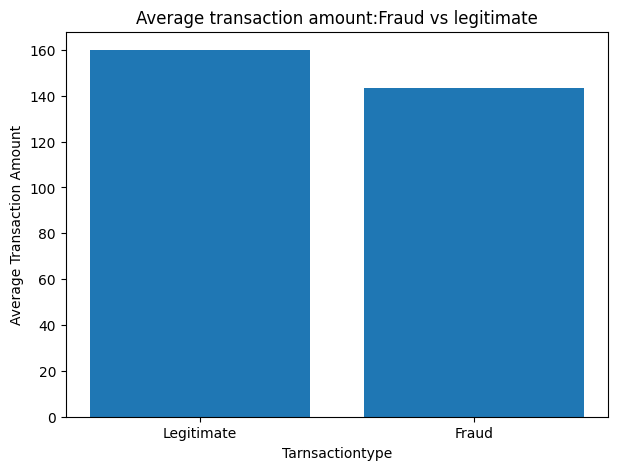

In [17]:
fraud_amount = df_sample.groupby("isFraud")["TransactionAmt"].mean()
plt.figure(figsize=(7,5))
plt.bar(
    ["Legitimate","Fraud"],
    fraud_amount.values
)
plt.title("Average transaction amount:Fraud vs legitimate")
plt.xlabel("Tarnsactiontype")
plt.ylabel("Average Transaction Amount")
plt.show()

In [19]:
pd.crosstab(
    df_sample["ProductCD"],
    df_sample["isFraud"],
    normalize = "index"
)*100

isFraud,0,1
ProductCD,,
C,95.031056,4.968944
H,100.000000,0.000000
R,96.551724,3.448276
S,88.461538,11.538462
W,99.562682,0.437318


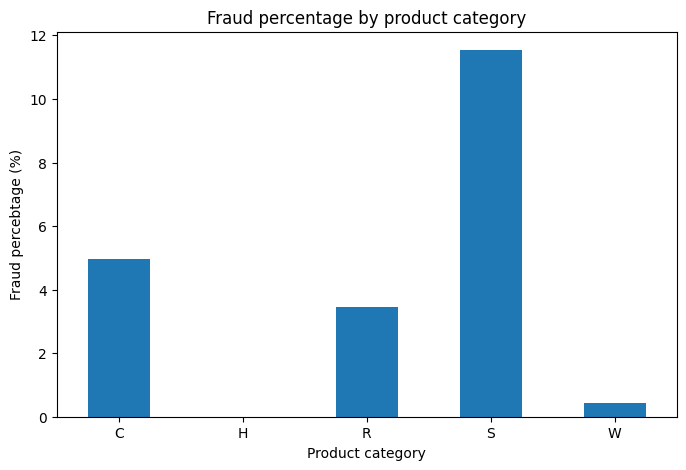

In [23]:
fraud_by_product = pd.crosstab(
    df_sample["ProductCD"],
    df_sample["isFraud"],
    normalize = "index"
)*100
fraud_by_product[1].plot(
    kind = "bar",
    figsize = (8,5)
)
plt.title("Fraud percentage by product category")
plt.xlabel("Product category")
plt.ylabel("Fraud percebtage (%)")
plt.xticks(rotation=0)
plt.show()
    

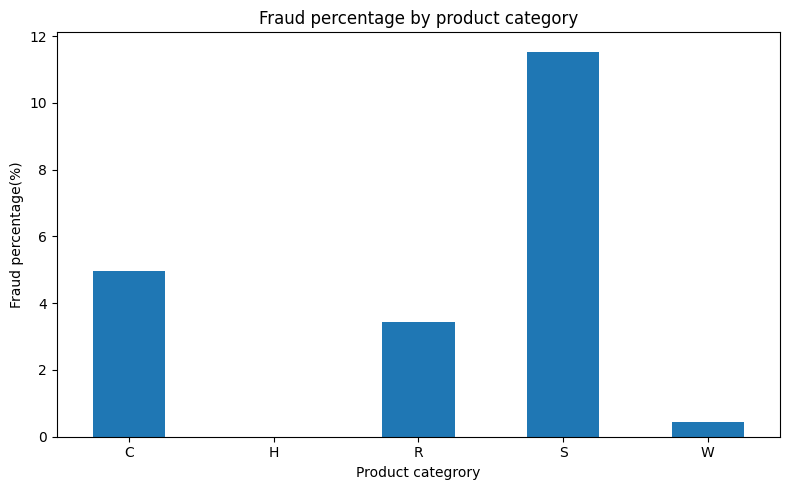

In [25]:
plt.figure(figsize=(8,5))
fraud_by_product[1].plot(kind = "bar")
plt.title("Fraud percentage by product category")
plt.xlabel("Product categrory")
plt.ylabel("Fraud percentage(%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../data/fraud_by_product.png",dpi=300)
plt.show()

In [27]:
#Fraud percentage by transaction amount
df_sample["AmountRange"]=pd.cut(
    df_sample["TransactionAmt"],
    bins = [0,50,100,250,500,1000,float("inf")],
    labels=["0-50","50-100","100-250","250-500","500-1000","1000+"]
)
fraud_by_amount = (
    df_sample.groupby("AmountRange",observed=True)["isFraud"].mean().mul(100)
    
)
print(fraud_by_amount)

AmountRange
0-50        1.699029
50-100      1.265823
100-250     1.351351
250-500     1.234568
500-1000    3.703704
1000+       0.000000
Name: isFraud, dtype: float64


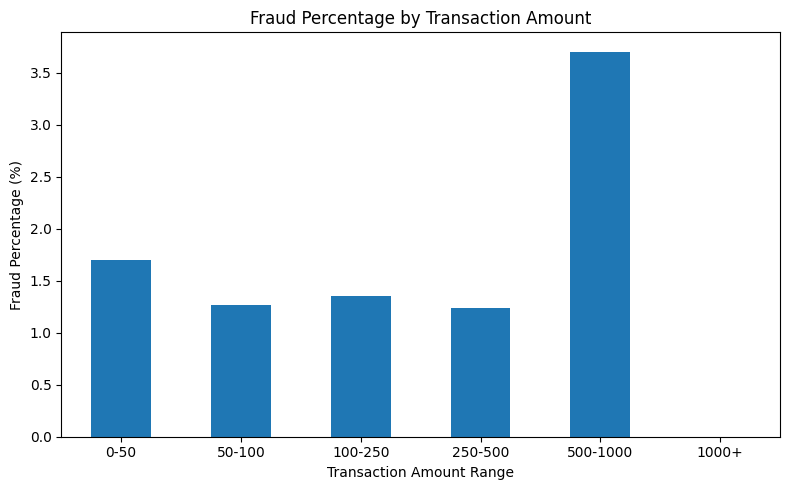

In [30]:
plt.figure(figsize=(8,5))

fraud_by_amount.plot(kind="bar")

plt.title("Fraud Percentage by Transaction Amount")
plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("../data/fraud_by_amount.png", dpi=300)

plt.show()

In [32]:
# Convert TransactionDT into hours of the day

df_sample["Hour"] = (df_sample["TransactionDT"] // 3600) % 24

print(df_sample[["TransactionDT", "Hour", "isFraud"]].head())

   TransactionDT  Hour  isFraud
0          86400     0        0
1          86401     0        0
2          86469     0        0
3          86499     0        0
4          86506     0        0


In [33]:
fraud_by_hour = (
    df_sample.groupby("Hour")["isFraud"]
    .mean()
    .mul(100)
)

print(fraud_by_hour)

Hour
0    0.438596
1    2.985075
2    0.000000
3    2.238806
4    3.260870
5    1.562500
6    1.098901
7    0.000000
Name: isFraud, dtype: float64


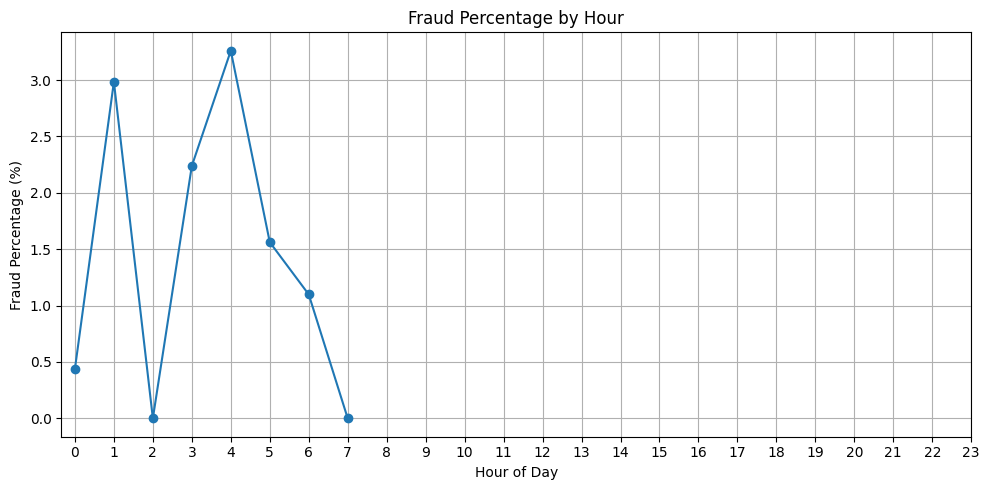

In [35]:
plt.figure(figsize=(10,5))

fraud_by_hour.plot(kind="line", marker="o")

plt.title("Fraud Percentage by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(range(24))
plt.grid(True)

plt.tight_layout()

plt.savefig("../data/fraud_by_hour.png", dpi=300)

plt.show()

In [36]:
print("========== FraudLens Day 1 Summary ==========")

print("Total sample transactions:", len(df_sample))

print("\nFraud transactions:")
print(df_sample["isFraud"].value_counts())

print("\nFraud percentage:")
print(df_sample["isFraud"].mean() * 100)

print("\nHighest fraud product category:")
print(fraud_by_product.idxmax())

print("\nHighest fraud amount range:")
print(fraud_by_amount.idxmax())

print("\nHighest fraud hour:")
print(fraud_by_hour.idxmax())

========== FraudLens Day 1 Summary ==========
Total sample transactions: 1000

Fraud transactions:
isFraud
0    985
1     15
Name: count, dtype: int64

Fraud percentage:
1.5

Highest fraud product category:
isFraud
0    H
1    S
dtype: object

Highest fraud amount range:
500-1000

Highest fraud hour:
4
